# Restaurant Dataset : Data Visualisation

### Level 3 - Task 3

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10,6)

In [2]:
df = pd.read_csv("../Engineered_Dataset.csv")

In [3]:
df.head()
df.shape

(9551, 29)

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10,6)
df = pd.read_csv("../Engineered_Dataset.csv")

In [5]:
display(df.head())

print("Shape:", df.shape)

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Rating text,Votes,Restaurant Name Length,Address Length,Cuisine Count,Has Table Booking,Has Online Delivery,Rating Category,Cost Per Vote,Has Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Excellent,314,16,71,3,1,0,Excellent,3.492063,1
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Excellent,591,16,67,1,1,0,Good,2.027027,1
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Very Good,270,22,56,4,1,0,Good,14.760148,1
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Excellent,365,4,70,2,0,0,Excellent,4.098361,1
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Excellent,229,11,64,2,1,0,Excellent,6.521739,1


Shape: (9551, 29)


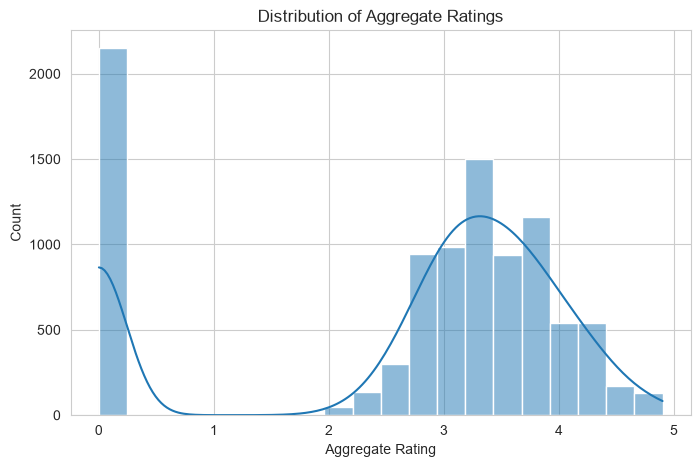

In [6]:
# Rating Distribution
plt.figure(figsize=(8,5))

sns.histplot(df["Aggregate rating"], bins=20, kde=True)

plt.title("Distribution of Aggregate Ratings")
plt.xlabel("Aggregate Rating")
plt.ylabel("Count")

plt.show()

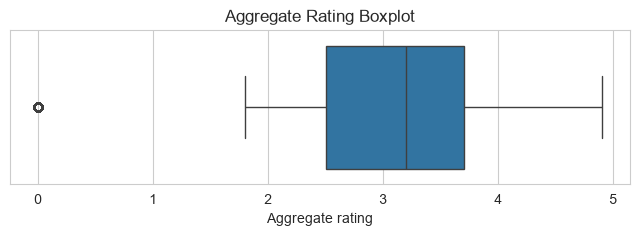

In [7]:
# Aggregate Rating BoxPlot
plt.figure(figsize=(8,2))

sns.boxplot(x=df["Aggregate rating"])

plt.title("Aggregate Rating Boxplot")

plt.show()

c:\Users\yadid\AppData\Local\Programs\Python\Python312\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 65533 (\N{REPLACEMENT CHARACTER}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


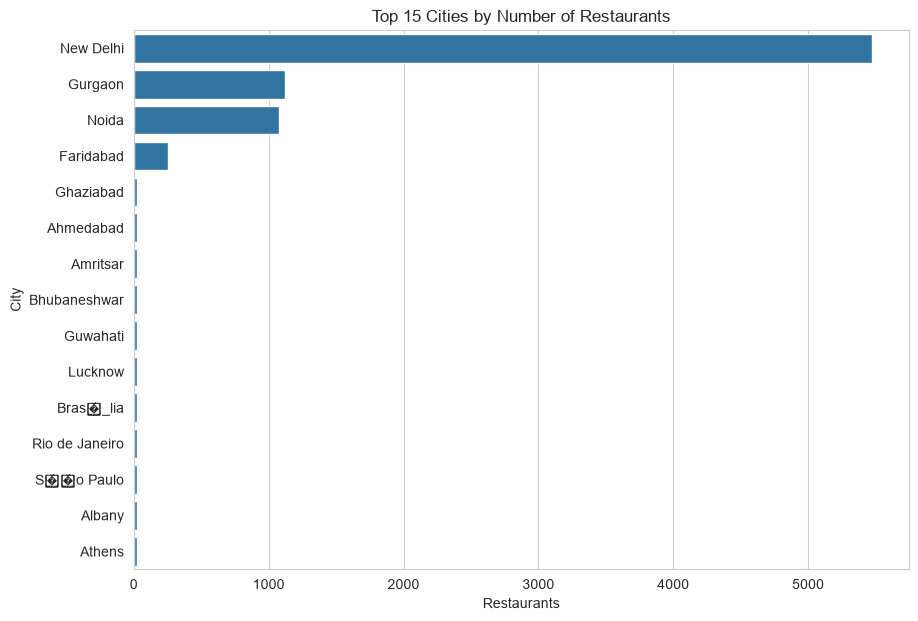

In [8]:
# Restaurant by City
plt.figure(figsize=(10,7))

city_counts = df["City"].value_counts().head(15)

sns.barplot(
    x=city_counts.values,
    y=city_counts.index
)

plt.title("Top 15 Cities by Number of Restaurants")
plt.xlabel("Restaurants")
plt.ylabel("City")

plt.show()

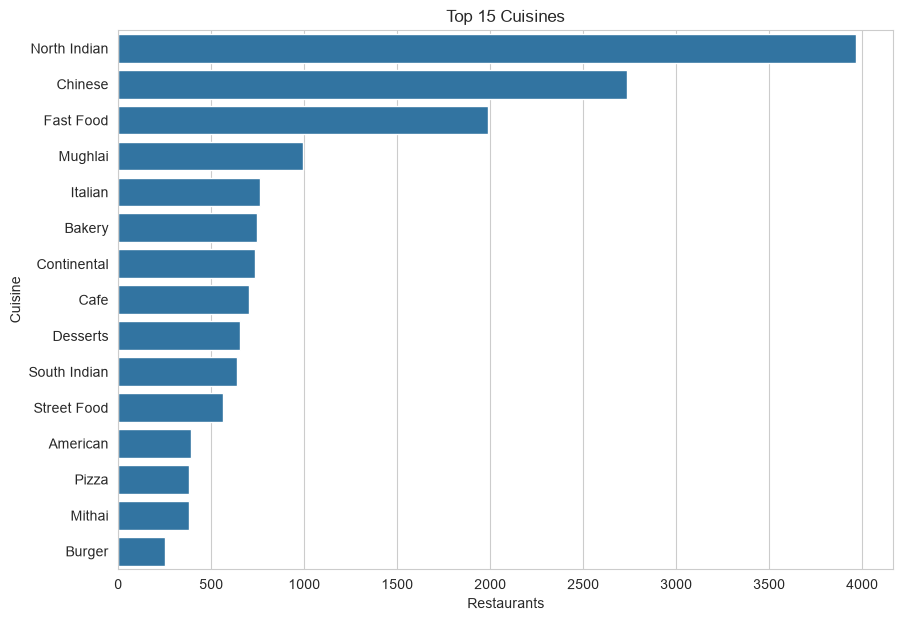

In [9]:
# Top Cuisines
cuisines = (
    df["Cuisines"]
    .dropna()
    .str.split(", ")
    .explode()
)

top_cuisines = cuisines.value_counts().head(15)

plt.figure(figsize=(10,7))

sns.barplot(
    x=top_cuisines.values,
    y=top_cuisines.index
)

plt.title("Top 15 Cuisines")

plt.xlabel("Restaurants")
plt.ylabel("Cuisine")

plt.show()

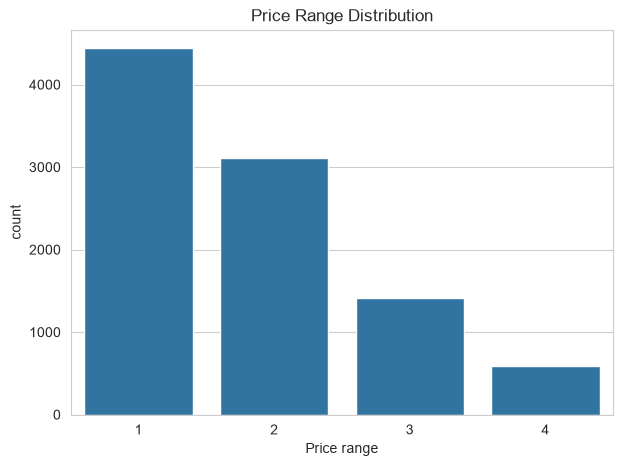

In [10]:
# Price Range Distribution
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x="Price range"
)

plt.title("Price Range Distribution")

plt.show()

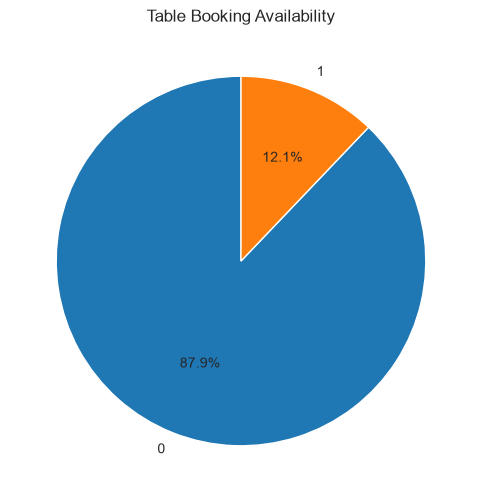

In [11]:
# Table Booking Availability
booking = df["Has Table Booking"].value_counts()

plt.figure(figsize=(6,6))

plt.pie(
    booking.values,
    labels=booking.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Table Booking Availability")

plt.show()

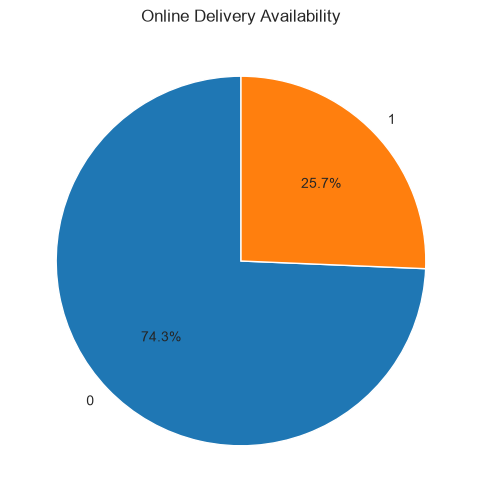

In [12]:
# Online Delivery Availability
delivery = df["Has Online Delivery"].value_counts()

plt.figure(figsize=(6,6))

plt.pie(
    delivery.values,
    labels=delivery.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Online Delivery Availability")

plt.show()

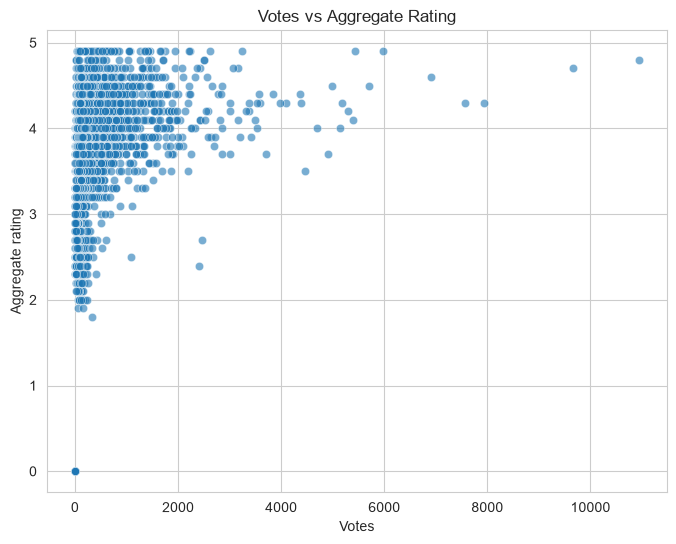

In [13]:
# Votes vs Aggregate Rating
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df,
    x="Votes",
    y="Aggregate rating",
    alpha=0.6
)

plt.title("Votes vs Aggregate Rating")

plt.show()

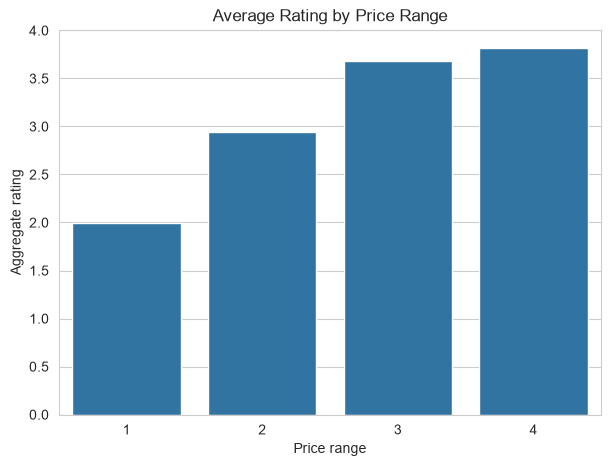

In [14]:
# Average Rating by Price Range
avg_rating = (
    df.groupby("Price range")["Aggregate rating"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(7,5))

sns.barplot(
    data=avg_rating,
    x="Price range",
    y="Aggregate rating"
)

plt.title("Average Rating by Price Range")

plt.show()

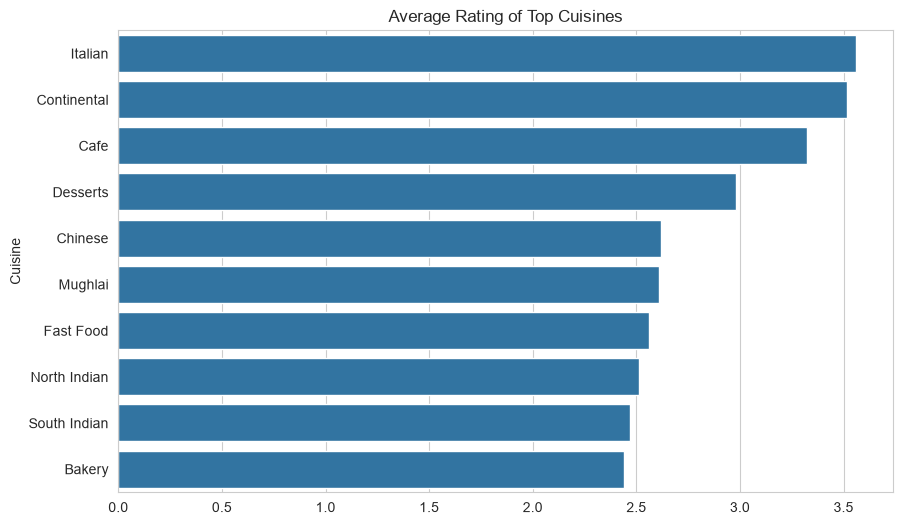

In [15]:
# Average Rating by Top Cuisines
top10 = cuisines.value_counts().head(10).index

cuisine_df = df.copy()

cuisine_df["Cuisine"] = cuisine_df["Cuisines"].str.split(", ")

cuisine_df = cuisine_df.explode("Cuisine")

cuisine_df = cuisine_df[cuisine_df["Cuisine"].isin(top10)]

avg = (
    cuisine_df.groupby("Cuisine")["Aggregate rating"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10,6))

sns.barplot(
    x=avg.values,
    y=avg.index
)

plt.title("Average Rating of Top Cuisines")

plt.show()

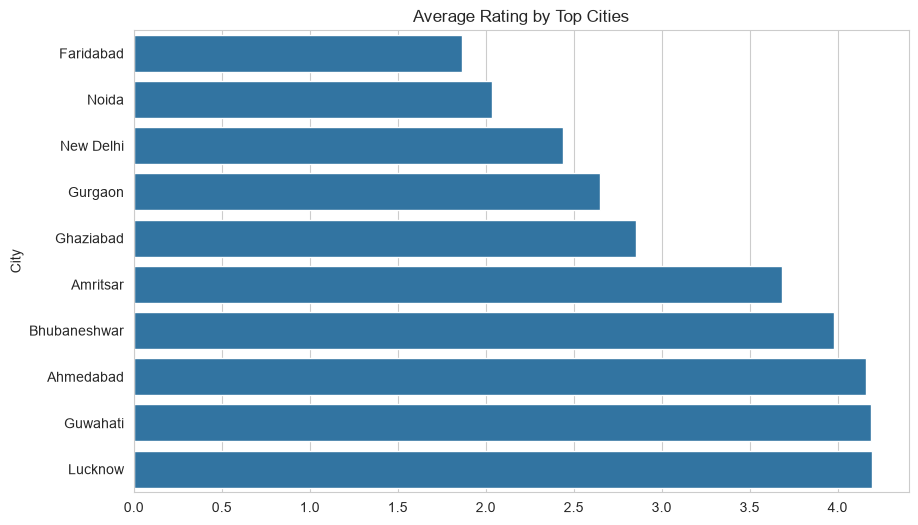

In [16]:
# Average Rating by Top Cities
top_cities = df["City"].value_counts().head(10).index

city_avg = (
    df[df["City"].isin(top_cities)]
    .groupby("City")["Aggregate rating"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(10,6))

sns.barplot(
    x=city_avg.values,
    y=city_avg.index
)

plt.title("Average Rating by Top Cities")

plt.show()

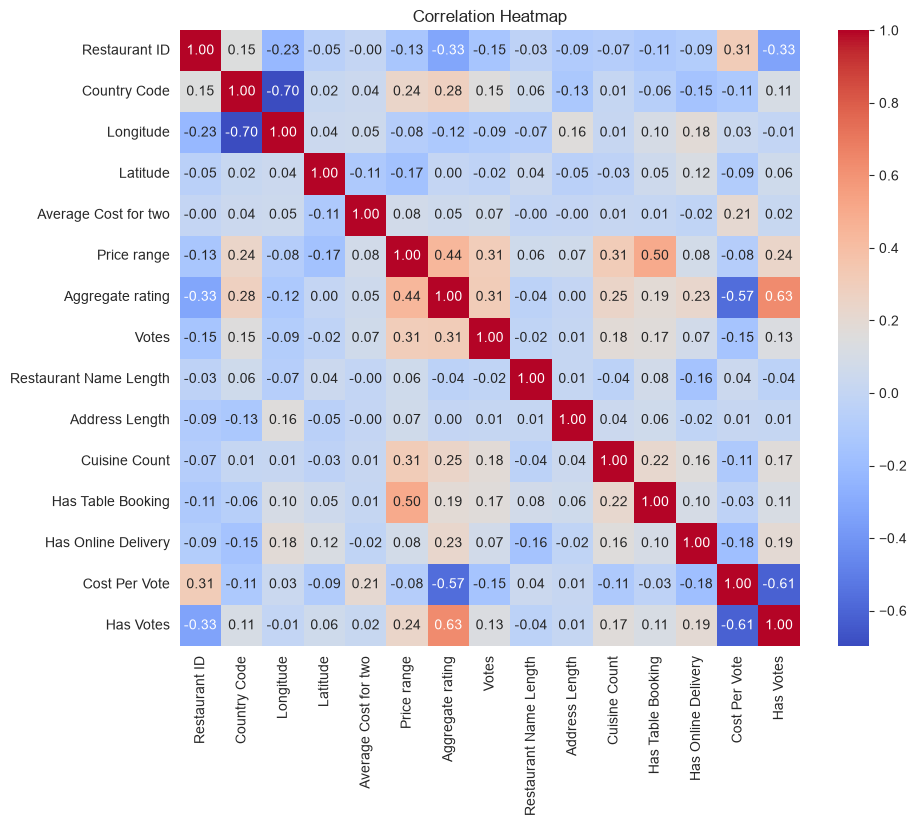

In [17]:
# Correlation HeatMap
numeric = df.select_dtypes(include="number")

plt.figure(figsize=(10,8))

sns.heatmap(
    numeric.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [18]:
# Restaurant Map
restaurant_map = folium.Map(
    location=[
        df["Latitude"].mean(),
        df["Longitude"].mean()
    ],
    zoom_start=5
)

sample = df.sample(1000, random_state=42)

for _, row in sample.iterrows():

    folium.CircleMarker(
        location=[row["Latitude"], row["Longitude"]],
        radius=3,
        popup=f"{row['Restaurant Name']}<br>Rating: {row['Aggregate rating']}",
        fill=True
    ).add_to(restaurant_map)

restaurant_map.save("restaurant_map.html")

### Dashboard Summary

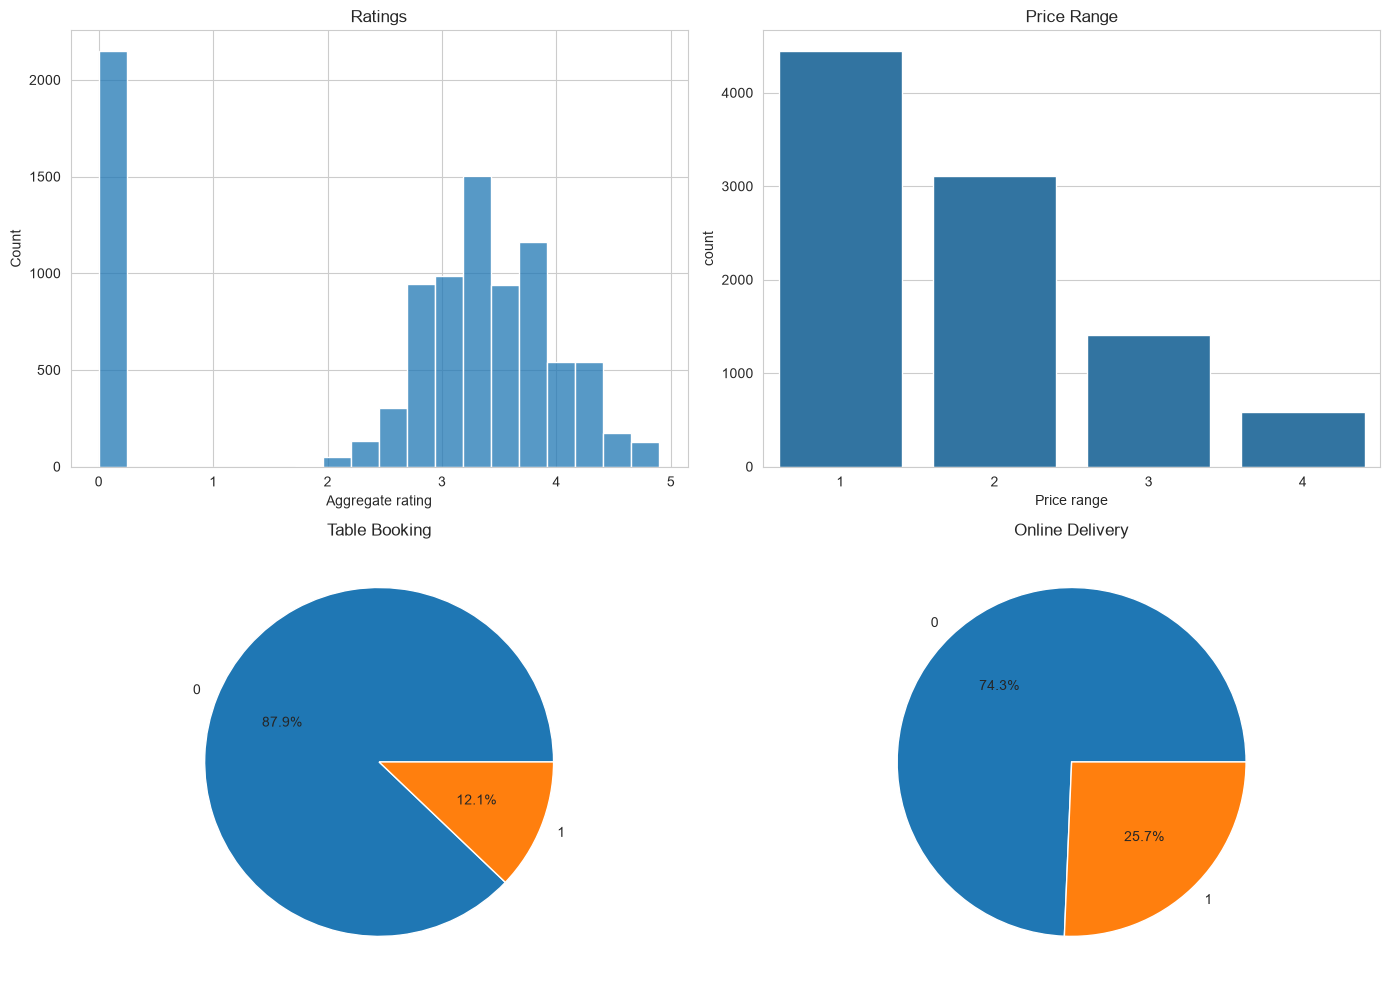

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(14,10))

# Rating Distribution
sns.histplot(df["Aggregate rating"], bins=20, ax=axes[0,0])
axes[0,0].set_title("Ratings")

# Price Range
sns.countplot(data=df, x="Price range", ax=axes[0,1])
axes[0,1].set_title("Price Range")

# Booking
df["Has Table Booking"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    ax=axes[1,0]
)
axes[1,0].set_ylabel("")
axes[1,0].set_title("Table Booking")

# Delivery
df["Has Online Delivery"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    ax=axes[1,1]
)
axes[1,1].set_ylabel("")
axes[1,1].set_title("Online Delivery")

plt.tight_layout()

plt.show()

## Final Observations

- Most restaurants have aggregate ratings between **3.0 and 4.5**, indicating generally positive customer feedback.
- Restaurant distribution is concentrated in a few cities and countries, showing geographical imbalance.
- A small number of cuisines dominate the dataset, while many others are less common.
- Most restaurants belong to the lower and medium price ranges, with relatively few expensive restaurants.
- Online delivery is more common than table booking, though both services vary across restaurants.
- Overall, the visualizations provide useful insights into restaurant ratings, pricing, cuisine popularity, and geographical distribution.